# Melbourne 20-minute neighbourhood — hexagon wedge map
**#30DayMapChallenge · Hexagons**

Each H3 hexagon is split into six triangular wedges, one per everyday need. A wedge's **area** shows how close that need is on foot: a full wedge means it's on your doorstep, no wedge means it's beyond the cutoff. A completely filled hexagon is a complete 20-minute neighbourhood.

Plan Melbourne defines a 20-minute neighbourhood as a 20-minute *return* walk: **800 m, or 10 minutes each way**. That's the default here (`CUTOFF_MIN = 10`).

**Pipeline**
1. Download the walk network and six amenity layers from OpenStreetMap (cached)
2. Multi-source Dijkstra per amenity type → walk minutes at every network node
3. Score fine H3 cells (res 10) from their nearest network node
4. Aggregate to res 8 for the city map
5. Render the city map and a street-level zoom

By default the data comes from **one OSM extract file** (BBBike Melbourne, auto-downloaded via `pyrosm`) processed locally, so there's no dependence on the often-overloaded Overpass API. The first run takes a few minutes; later runs use `./cache`.

In [247]:
# Run once
# %pip install osmnx pyrosm h3 scipy matplotlib pyproj shapely geopandas

In [248]:
from __future__ import annotations

import math
from pathlib import Path

import h3
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from matplotlib.collections import PolyCollection
from matplotlib.patches import Rectangle
from pyproj import Transformer
from scipy.sparse import csr_matrix
from scipy.sparse.csgraph import dijkstra
from scipy.spatial import cKDTree
from shapely.geometry import LineString, MultiPolygon, Point, Polygon
from shapely.ops import transform as shp_transform
from IPython.display import Image, display


## Config
Change these and re-run from here. Cache files are keyed by radius and cutoff, so changing either one triggers a fresh download.

In [250]:
# Where the OSM data comes from:
#   "pbf"      = one downloaded OSM extract file, processed locally (reliable, recommended)
#   "overpass" = live Overpass API queries (often overloaded)
DATA_SOURCE = "pbf"
PBF_PATH = None   # None = auto-download the BBBike Melbourne extract into ./cache
                  # or point to your own file, e.g. r"C:\data\melbourne.osm.pbf"

CENTER_LATLNG = (-37.8136, 144.9631)   # Melbourne CBD
RADIUS_KM = 25                          # study area radius (bigger = heavier graph)

# Official Plan Melbourne definition: 20-minute *return* trip = 800 m / 10 min each way.
# Set to 20 for a "20 minutes one-way" (more generous) version.
CUTOFF_MIN = 10
WALK_M_PER_MIN = 80                     # ~4.8 km/h

FINE_RES = 10                           # computation grid (~0.015 km² per cell)
CITY_RES = 7                            # whole-city map (~5 km² per cell)
INNER_RES = 8                           # inner-city map (~0.74 km² per cell)
INNER_RADIUS_KM = 10
MIN_CHILD_SHARE = 0.2                   # drop coarse hexes where <20% of their fine children are walkable

CELL_SNAP_MAX_M = 120                   # fine cells further than this from any path = not walkable (water, rail yards, airport)
SOURCE_SNAP_MAX_M = 300                 # amenities further than this from any path are ignored
PARK_EDGE_STEP_M = 50                   # sample park boundaries every N m (centroids of big parks are misleading)

# Street-level insets (res-10 hexes). Mix of strong and weak areas; swap in any from the
# suburb ranking printed in section 7.
INSETS = [
    {"name": "Fitzroy",       "latlng": (-37.7984, 144.9783), "note": "Inner city · trams"},
    {"name": "Box Hill",      "latlng": (-37.8189, 145.1218), "note": "Suburban hub · train"},
    {"name": "Sunshine West", "latlng": (-37.7890, 144.8180), "note": "State 20-minute pilot area"},
    {"name": "Wheelers Hill", "latlng": (-37.9050, 145.1890), "note": "Outer east · no train"},
]
INSET_RES = 9                           # inset hexes (~0.4 km wide): big enough to read the wedges
INSET_RADIUS_KM = 2.0                   # half-width of each inset → ~10–12 hexes across
SHOW_COUNCILS = False                   # council outlines + names (off = cleaner poster)
SHOW_YARRA = False                      # Yarra River as a landmark line
LAYER_RES = 8                           # resolution of the six single-need maps
SHOW_RAIL = False                       # train/tram lines on the maps
# Greater Melbourne's 31 councils. Any missing from the extract (big outer ones get cut at its edge)
# are fetched from OSM's Nominatim place search instead.
METRO_COUNCILS = ["Banyule", "Bayside", "Boroondara", "Brimbank", "Cardinia", "Casey", "Darebin",
                  "Frankston", "Glen Eira", "Greater Dandenong", "Hobsons Bay", "Hume", "Kingston", "Knox",
                  "Manningham", "Maribyrnong", "Maroondah", "Melbourne", "Melton", "Merri-bek", "Monash",
                  "Moonee Valley", "Mornington Peninsula", "Nillumbik", "Port Phillip", "Stonnington",
                  "Whitehorse", "Whittlesea", "Wyndham", "Yarra", "Yarra Ranges"]
COUNCIL_ADMIN_LEVEL = "6"               # OSM admin level for Australian councils (LGAs)
GHOST_ALPHA = 0.16                      # faint full-size wedge behind each score wedge (0 = off)

CRS_PROJ = "EPSG:7855"                  # GDA2020 / MGA zone 55 (metres)
CACHE = Path("cache")
OUT = Path("output")

# Six needs, ordered so related themes sit next to each other around the hexagon.
# Colours: Okabe-Ito (colour-blind safe).
CATEGORIES = {
    "transit": {
        "label": "Train / tram",          # bus stops are everywhere, so they'd fill every hex
        "color": "#56B4E9",
        "tags": {"railway": ["station", "halt", "tram_stop"]},
    },
    "groceries": {
        "label": "Groceries",
        "color": "#E69F00",
        "tags": {"shop": ["supermarket", "greengrocer", "grocery", "convenience"]},
    },
    "health": {
        "label": "GP / pharmacy",
        "color": "#D55E00",
        "tags": {
            "amenity": ["doctors", "clinic", "pharmacy", "hospital"],
            "healthcare": ["doctor", "clinic", "pharmacy", "centre"],
        },
    },
    "school": {
        "label": "School / childcare",
        "color": "#F0E442",
        "tags": {"amenity": ["school", "kindergarten", "childcare"]},
    },
    "community": {
        "label": "Community space",
        "color": "#CC79A7",
        "tags": {"amenity": ["library", "community_centre", "arts_centre", "place_of_worship"]},
    },
    "park": {
        "label": "Park / playground",
        "color": "#009E73",
        "tags": {"leisure": ["park", "playground", "garden", "recreation_ground"]},
    },
}
KEYS = list(CATEGORIES)

import hashlib, json
# changing any tags above changes this hash, so amenity/score caches rebuild automatically
TAGS_HASH = hashlib.md5(json.dumps({k: v["tags"] for k, v in CATEGORIES.items()}, sort_keys=True).encode()).hexdigest()[:6]

BG = "#0e1014"
FG = "#e8e6e1"
MUTED = "#8a8f98"

to_proj = Transformer.from_crs("EPSG:4326", CRS_PROJ, always_xy=True)
to_wgs = Transformer.from_crs(CRS_PROJ, "EPSG:4326", always_xy=True)


# ── Overpass (OSM download server) settings ───────────────────────────────
# The main server (overpass-api.de) is often overloaded → 502/504 errors.
OVERPASS_MIRRORS = [
    "https://overpass.kumi.systems/api",
    "https://overpass.private.coffee/api",
    "https://overpass-api.de/api",
]
import time
if DATA_SOURCE == "overpass":
    import osmnx as ox
    ox.settings.use_cache = True                  # finished chunks are cached → retries resume
    ox.settings.requests_timeout = 600
    ox.settings.max_query_area_size = 250_000_000  # ~250 km² per request: smaller, kinder queries
    ox.settings.overpass_url = OVERPASS_MIRRORS[0]


def with_retry(fn, *args, tries=8, wait=20, **kwargs):
    """Retry busy-server errors with exponential backoff, rotating mirrors."""
    import osmnx as ox
    for n in range(tries):
        try:
            return fn(*args, **kwargs)
        except Exception as exc:
            msg = str(exc).lower()
            busy = any(s in msg for s in ("502", "503", "504", "429", "timeout", "timed out",
                                          "capacity", "too many", "connection"))
            if not busy or n == tries - 1:
                raise
            ox.settings.overpass_url = OVERPASS_MIRRORS[(n + 1) % len(OVERPASS_MIRRORS)]
            print(f"  server busy → retry {n + 1}/{tries - 1} in {wait}s via {ox.settings.overpass_url}")
            time.sleep(wait)
            wait = min(wait * 2, 300)


## 1. Study area and OSM downloads
The download area is buffered by the cutoff distance, so hexes at the edge still see amenities just outside. Parks are sampled along their **boundaries**: the centroid of a big park can be a kilometre from its nearest gate.

In [252]:
def study_area(buffer_m: float = 0) -> tuple[Polygon, Polygon]:
    """Circle around the centre. Returns (projected polygon, WGS84 polygon)."""
    cx, cy = to_proj.transform(CENTER_LATLNG[1], CENTER_LATLNG[0])
    poly_proj = Point(cx, cy).buffer(RADIUS_KM * 1000 + buffer_m, resolution=64)
    poly_wgs = shp_transform(to_wgs.transform, poly_proj)
    return poly_proj, poly_wgs


def download_buffer_m() -> float:
    # Paths and amenities just outside the study area still count for edge hexes
    return CUTOFF_MIN * WALK_M_PER_MIN + 400


def load_graph():
    """Walk network, projected, cached as GraphML."""
    import osmnx as ox

    path = CACHE / f"walk_r{RADIUS_KM}_c{CUTOFF_MIN}.graphml"
    if path.exists():
        print(f"· loading cached graph {path}")
        return ox.load_graphml(path)
    _, poly_wgs = study_area(download_buffer_m())
    print("· downloading walk network (slow the first time)…")
    G = with_retry(ox.graph_from_polygon, poly_wgs, network_type="walk", simplify=True, retain_all=False)
    G = ox.project_graph(G, to_crs=CRS_PROJ)
    ox.save_graphml(G, path)
    return G


def edges_to_matrix(n, u_idx, v_idx, meters):
    """Symmetric sparse matrix of walk minutes; parallel edges keep the shortest."""
    a, b = np.minimum(u_idx, v_idx), np.maximum(u_idx, v_idx)
    e = pd.DataFrame({"r": a, "c": b, "m": np.asarray(meters, float) / WALK_M_PER_MIN})
    e = e[e["r"] != e["c"]].groupby(["r", "c"], as_index=False)["m"].min()
    e["m"] = e["m"].clip(lower=1e-6)  # zero-length edges would be dropped as "no edge"
    return csr_matrix((e["m"].values, (e["r"].values, e["c"].values)), shape=(n, n))


def graph_arrays(G):
    """Node coordinates + symmetric sparse matrix of walk minutes."""
    nodes = list(G.nodes)
    idx = {n: i for i, n in enumerate(nodes)}
    xy = np.array([[G.nodes[n]["x"], G.nodes[n]["y"]] for n in nodes], dtype=float)

    us, vs, lens = [], [], []
    for u, v, d in G.edges(data=True):
        us.append(idx[u]); vs.append(idx[v]); lens.append(float(d.get("length", 0)))
    return xy, edges_to_matrix(len(nodes), np.array(us), np.array(vs), np.array(lens))


def _feature_points(gdf, is_park: bool) -> np.ndarray:
    """Turn OSM features (points / lines / polygons) into representative xy points."""
    pts = []
    for geom in gdf.geometry:
        if geom is None or geom.is_empty:
            continue
        if isinstance(geom, Point):
            pts.append((geom.x, geom.y))
        elif isinstance(geom, (Polygon, MultiPolygon)):
            if is_park:
                parts = geom.geoms if isinstance(geom, MultiPolygon) else [geom]
                for p in parts:
                    ring = p.exterior
                    n = max(int(ring.length // PARK_EDGE_STEP_M), 1)
                    for k in range(n):
                        q = ring.interpolate(k * PARK_EDGE_STEP_M)
                        pts.append((q.x, q.y))
            else:
                q = geom.representative_point()
                pts.append((q.x, q.y))
        elif isinstance(geom, LineString):
            q = geom.interpolate(0.5, normalized=True)
            pts.append((q.x, q.y))
        else:
            q = geom.representative_point()
            pts.append((q.x, q.y))
    return np.array(pts, dtype=float).reshape(-1, 2)


def load_amenities() -> dict[str, np.ndarray]:
    """Projected xy points per category, cached as .npz."""
    path = CACHE / f"amenities_{DATA_SOURCE}_r{RADIUS_KM}_c{CUTOFF_MIN}_{TAGS_HASH}.npz"
    if path.exists():
        print(f"· loading cached amenities {path}")
        z = np.load(path)
        return {k: z[k] for k in KEYS}

    if DATA_SOURCE == "pbf":
        out = amenities_from_pbf()
        np.savez_compressed(path, **out)
        return out

    import osmnx as ox

    _, poly_wgs = study_area(download_buffer_m())
    out = {}
    for key, cfg in CATEGORIES.items():
        print(f"· downloading {key}…")
        try:
            gdf = with_retry(ox.features_from_polygon, poly_wgs, cfg["tags"])
        except Exception as exc:  # osmnx raises if nothing matches
            print(f"  ! {key}: {exc}")
            out[key] = np.empty((0, 2))
            continue
        if "access" in gdf.columns:  # private gardens, school-only playgrounds, etc.
            gdf = gdf[~gdf["access"].isin(["private", "no"])]
        gdf = gdf.to_crs(CRS_PROJ)
        out[key] = _feature_points(gdf, is_park=(key == "park"))
        print(f"  {len(gdf):,} features → {len(out[key]):,} source points")
    np.savez_compressed(path, **out)
    return out


# ── Offline route: one OSM extract (.osm.pbf) read locally with pyrosm ─────
_OSM = None


def _pbf():
    global _OSM
    if _OSM is None:
        from pyrosm import OSM, get_data
        fp = PBF_PATH or get_data("Melbourne", directory=str(CACHE))
        _, poly_wgs = study_area(download_buffer_m())
        print(f"· reading {fp}")
        _OSM = OSM(str(fp), bounding_box=poly_wgs)
    return _OSM


def network_from_pbf():
    print("· building walk network from extract (a few minutes)…")
    nodes, edges = _pbf().get_network(network_type="walking", nodes=True)
    x, y = to_proj.transform(nodes["lon"].values, nodes["lat"].values)
    xy = np.column_stack([x, y])
    idx = pd.Series(np.arange(len(nodes)), index=nodes["id"].values)
    idx = idx[~idx.index.duplicated()]
    e = edges[edges["u"].isin(idx.index) & edges["v"].isin(idx.index)]
    M = edges_to_matrix(len(nodes), idx[e["u"]].values, idx[e["v"]].values, e["length"].values)

    # warn if the extract doesn't cover the whole study area
    poly_proj, _ = study_area()
    minx, miny, maxx, maxy = poly_proj.bounds
    if xy[:, 0].min() > minx + 500 or xy[:, 0].max() < maxx - 500 or xy[:, 1].min() > miny + 500 or xy[:, 1].max() < maxy - 500:
        print("  ! the extract doesn't cover the full study area: lower RADIUS_KM or use a bigger extract")
    return xy, M


def amenities_from_pbf() -> dict[str, np.ndarray]:
    import geopandas as gpd
    osm = _pbf()
    out = {}
    for key, cfg in CATEGORIES.items():
        parts = []
        for tag, vals in cfg["tags"].items():
            vals = vals if isinstance(vals, list) else [vals]
            g = osm.get_data_by_custom_criteria(custom_filter={tag: vals}, osm_keys_to_keep=[tag],
                                                tags_as_columns=[tag, "access"])
            if g is not None and len(g):
                g = g.copy()
                if "access" not in g.columns:
                    g["access"] = None
                parts.append(g[["geometry", "access"]])
        if not parts:
            print(f"  ! {key}: nothing found")
            out[key] = np.empty((0, 2))
            continue
        gdf = gpd.GeoDataFrame(pd.concat(parts, ignore_index=True), geometry="geometry")
        if gdf.crs is None:
            gdf = gdf.set_crs("EPSG:4326")
        gdf = gdf[~gdf["access"].isin(["private", "no"])].to_crs(CRS_PROJ)
        out[key] = _feature_points(gdf, is_park=(key == "park"))
        print(f"· {key:<10} {len(gdf):>7,} features → {len(out[key]):,} source points")
    return out


def load_network():
    """(node xy, minutes matrix), cached after the first build."""
    from scipy.sparse import load_npz, save_npz
    stem = CACHE / f"net_{DATA_SOURCE}_r{RADIUS_KM}_c{CUTOFF_MIN}"
    mpath, xpath = stem.with_suffix(".npz"), Path(str(stem) + "_xy.npy")
    if mpath.exists() and xpath.exists():
        print(f"· loading cached network {mpath}")
        return np.load(xpath), load_npz(mpath)
    xy, M = network_from_pbf() if DATA_SOURCE == "pbf" else graph_arrays(load_graph())
    save_npz(mpath, M)
    np.save(xpath, xy)
    return xy, M


## 2. Walk times
One Dijkstra run per category, starting from *all* amenities of that type at once. That's six runs in total, not one per hexagon.

In [254]:
def walk_times(M, tree: cKDTree, src_xy: np.ndarray) -> np.ndarray:
    """Minutes from every node to the nearest source (inf beyond cutoff)."""
    n = M.shape[0]
    if len(src_xy) == 0:
        return np.full(n, np.inf)
    d, i = tree.query(src_xy)
    src = np.unique(i[d <= SOURCE_SNAP_MAX_M])
    if len(src) == 0:
        return np.full(n, np.inf)
    return dijkstra(M, directed=False, indices=src, min_only=True, limit=CUTOFF_MIN + 1)


## 3. Score fine cells and aggregate
Res 10 cells (~150 m wide) are scored from their nearest path node. Cells more than 120 m from any path (water, rail yards, the airport) are dropped. Coarser maps average their res 10 children, so every resolution comes from the same numbers.

In [256]:
def score_fine_cells(node_xy, node_minutes: dict[str, np.ndarray], tree: cKDTree) -> pd.DataFrame:
    _, poly_wgs = study_area()
    cells = list(h3.geo_to_cells(poly_wgs, FINE_RES))
    print(f"· {len(cells):,} res-{FINE_RES} cells in study area")

    latlng = np.array([h3.cell_to_latlng(c) for c in cells])
    x, y = to_proj.transform(latlng[:, 1], latlng[:, 0])
    d, i = tree.query(np.column_stack([x, y]))
    keep = d <= CELL_SNAP_MAX_M
    print(f"· {keep.sum():,} walkable cells (centroid within {CELL_SNAP_MAX_M} m of a path)")

    df = pd.DataFrame({"cell": np.array(cells)[keep]})
    access_min = d[keep] / WALK_M_PER_MIN  # walk from cell centre onto the network
    for k in KEYS:
        t = node_minutes[k][i[keep]] + access_min
        df[f"min_{k}"] = t
        df[k] = 1 - np.minimum(t, CUTOFF_MIN) / CUTOFF_MIN
    return df


def aggregate(df: pd.DataFrame, res: int) -> pd.DataFrame:
    """Mean score of fine children per coarser parent cell."""
    g = df.assign(parent=[h3.cell_to_parent(c, res) for c in df["cell"]])
    agg = g.groupby("parent")[KEYS].mean()
    agg["n"] = g.groupby("parent").size()
    min_n = max(1, round(MIN_CHILD_SHARE * 7 ** (FINE_RES - res)))
    agg = agg[agg["n"] >= min_n].reset_index().rename(columns={"parent": "cell"})
    return agg


## 4. Rendering
Wedges scale by `sqrt(score)`, so triangle **area** is proportional to the score. Vertices are re-ordered from a shared reference angle, so wedge *k* points the same way in every hexagon.

In [298]:
def _cell_vertices(cell: str) -> np.ndarray:
    b = np.array(h3.cell_to_boundary(cell))  # (lat, lng)
    x, y = to_proj.transform(b[:, 1], b[:, 0])
    return np.column_stack([x, y])


def _ordered(verts: np.ndarray, ref_angle: float):
    """Sort vertices counter-clockwise, starting at the one nearest ref_angle.
    Keeps 'wedge k = category k' pointing the same way in every hexagon."""
    c = verts.mean(axis=0)
    ang = np.arctan2(verts[:, 1] - c[1], verts[:, 0] - c[0])
    order = np.argsort(ang)
    v, a = verts[order], ang[order]
    diff = np.abs((a - ref_angle + np.pi) % (2 * np.pi) - np.pi)
    start = int(np.argmin(diff))
    return c, np.roll(v, -start, axis=0)


def _reference_angle(cell: str) -> float:
    v = _cell_vertices(cell)
    c = v.mean(axis=0)
    ang = np.arctan2(v[:, 1] - c[1], v[:, 0] - c[0])
    # first vertex counter-clockwise from east
    return float(np.sort(ang % (2 * np.pi))[0])


def build_patches(df: pd.DataFrame, ref_angle: float, gap=0.93):
    """Hex outlines, score wedges and full-size 'ghost' wedges (the empty slots)."""
    outlines, wedges, colors, ghosts, gcolors = [], [], [], [], []
    palette = [CATEGORIES[k]["color"] for k in KEYS]
    scores = df[KEYS].to_numpy()
    for cell, s in zip(df["cell"], scores):
        c, v = _ordered(_cell_vertices(cell), ref_angle)
        outlines.append(v)
        for k in range(6):
            a, b = v[k], v[(k + 1) % 6]
            ghosts.append([c, c + gap * (a - c), c + gap * (b - c)])
            gcolors.append(palette[k])
            sc = s[k]
            if not np.isfinite(sc) or sc <= 0.005:
                continue
            f = gap * math.sqrt(sc)  # area-honest: triangle area ∝ score
            wedges.append([c, c + f * (a - c), c + f * (b - c)])
            colors.append(palette[k])
    return outlines, wedges, colors, ghosts, gcolors


def draw_hexes(ax, df, ref_angle, outline_lw=0.3):
    outlines, wedges, colors, ghosts, gcolors = build_patches(df, ref_angle)
    ax.add_collection(PolyCollection(outlines, facecolors="#15181d", edgecolors="#2c3038", linewidths=outline_lw, zorder=1))
    if GHOST_ALPHA > 0:
        ax.add_collection(PolyCollection(ghosts, facecolors=gcolors, edgecolors="none", alpha=GHOST_ALPHA, zorder=1.5))
    ax.add_collection(PolyCollection(wedges, facecolors=colors, edgecolors="none", zorder=2))
    ax.set_aspect("equal")
    ax.set_facecolor(BG)
    ax.axis("off")


def draw_legend(fig, rect, ref_angle, fs=9):
    ax = fig.add_axes(rect)
    ax.set_facecolor(BG)
    ax.set_aspect("equal")
    ax.axis("off")
    angs = ref_angle + np.arange(6) * np.pi / 3
    v = np.column_stack([np.cos(angs), np.sin(angs)])
    c = np.zeros(2)
    ax.add_patch(plt.Polygon(v, closed=True, fc="#1a1d23", ec="#3a3f48", lw=0.8))
    for k, key in enumerate(KEYS):
        a, b = v[k], v[(k + 1) % 6]
        col = CATEGORIES[key]["color"]
        ax.add_patch(plt.Polygon([c, c + 0.93 * (a - c), c + 0.93 * (b - c)], closed=True, fc=col, ec="none", alpha=GHOST_ALPHA))
        f = 0.93 * math.sqrt([1, 0.6, 0.3, 0.8, 0.45, 0.15][k])   # example scores, so the legend shows partial wedges
        ax.add_patch(plt.Polygon([c, c + f * (a - c), c + f * (b - c)], closed=True, fc=col, ec="none"))
        mid = ref_angle + (k + 0.5) * np.pi / 3
        lx, ly = 1.2 * math.cos(mid), 1.2 * math.sin(mid)
        ha = "left" if lx > 0.15 else "right" if lx < -0.15 else "center"
        ax.text(lx, ly, CATEGORIES[key]["label"], color=FG, fontsize=fs, ha=ha, va="center")
    ax.set_xlim(-2.6, 2.6)
    ax.set_ylim(-1.8, 1.75)
    # size key: half-size wedge = half the cutoff
    ax.text(0, -1.75, f"Bright wedge = walking access (full = on your doorstep)\ndim slot = beyond a {2 * CUTOFF_MIN}-min round trip",
            color=MUTED, fontsize=fs * 0.82, ha="center", va="center")


def render(df, path, title, subtitle, extent=None, legend=True, zoom_box=None, ref_angle=0.0):
    fig = plt.figure(figsize=(14, 15), facecolor=BG)
    ax = fig.add_axes([0.03, 0.14, 0.94, 0.76])
    draw_hexes(ax, df, ref_angle, outline_lw=0.3 if extent is None else 0.5)
    if extent is not None:
        ax.set_xlim(extent[0], extent[2])
        ax.set_ylim(extent[1], extent[3])
    else:
        ax.autoscale_view()
    if zoom_box is not None:
        x0, y0, x1, y1 = zoom_box
        ax.add_patch(Rectangle((x0, y0), x1 - x0, y1 - y0, fill=False, ec=FG, lw=1, ls="--"))

    fig.text(0.05, 0.955, title, color=FG, fontsize=26, ha="left", va="center", weight="bold")
    fig.text(0.05, 0.925, subtitle, color=MUTED, fontsize=12, ha="left", va="center")
    if legend:
        draw_legend(fig, [0.60, 0.01, 0.38, 0.11], ref_angle)
    fig.text(0.05, 0.03,
             f"Walk times on the OSM pedestrian network at {WALK_M_PER_MIN} m/min · H3 hexagons · "
             f"wedge area ∝ score\nData © OpenStreetMap contributors · #30DayMapChallenge — Hexagons",
             color=MUTED, fontsize=8.5, ha="left", va="center")
    fig.savefig(path, dpi=300, facecolor=BG)
    plt.close(fig)
    print(f"✓ wrote {path}")


## 5. Compute
This is the slow cell the first time. After that it reads `cache/scores_*.csv`.

In [260]:
def compute(G=None, amenities=None) -> pd.DataFrame:
    """Steps 1–3. Returns the fine-cell score table (also cached as CSV)."""
    path = CACHE / f"scores_{DATA_SOURCE}_r{RADIUS_KM}_c{CUTOFF_MIN}_res{FINE_RES}_{TAGS_HASH}.csv"
    if path.exists() and G is None:
        print(f"· loading cached scores {path}")
        return pd.read_csv(path)

    node_xy, M = graph_arrays(G) if G is not None else load_network()
    amenities = amenities if amenities is not None else load_amenities()
    print(f"· graph: {M.shape[0]:,} nodes, {M.nnz:,} edges")
    tree = cKDTree(node_xy)

    node_minutes = {}
    for k in KEYS:
        node_minutes[k] = walk_times(M, tree, amenities[k])
        ok = np.isfinite(node_minutes[k]) & (node_minutes[k] <= CUTOFF_MIN)
        print(f"· {k:<10} {len(amenities[k]):>7,} sources · {ok.mean():5.1%} of nodes within {CUTOFF_MIN} min")

    df = score_fine_cells(node_xy, node_minutes, tree)
    df.to_csv(path, index=False)
    return df


CACHE.mkdir(exist_ok=True)
OUT.mkdir(exist_ok=True)

fine = compute()
complete = (fine[KEYS] > 0).all(axis=1).mean()
print(f"{complete:.1%} of walkable res-{FINE_RES} cells reach all six needs within {CUTOFF_MIN} min")
# projected centroid of each fine cell (used for insets and suburb assignment)
_ll = np.array([h3.cell_to_latlng(c) for c in fine["cell"]])
fine["fx"], fine["fy"] = to_proj.transform(_ll[:, 1], _ll[:, 0])
fine["complete"] = (fine[KEYS] > 0).all(axis=1)
fine.head()

· loading cached scores cache\scores_pbf_r25_c10_res10_0b338c.csv
10.5% of walkable res-10 cells reach all six needs within 10 min


,cell,min_transit,transit,min_groceries,groceries,min_health,health,min_school,school,min_community,community,min_park,park,fx,fy,complete
0,8abe6351d45ffff,inf,0.000000,inf,0.000000,inf,0.00000,6.072238,0.392776,inf,0.000000,2.021338,0.797866,335039.728352,5.825032e+06,False
1,8abe63cc6b5ffff,7.284086,0.271591,3.913911,0.608609,6.681999,0.33180,8.177261,0.182274,4.383861,0.561614,1.076899,0.892310,333609.381157,5.802209e+06,True
2,8abe6356d867fff,10.355149,0.000000,6.489299,0.351070,6.489299,0.35107,7.439699,0.256030,7.137587,0.286241,4.124387,0.587561,314704.115229,5.808092e+06,False
3,8abe63503d0ffff,inf,0.000000,inf,0.000000,inf,0.00000,inf,0.000000,inf,0.000000,2.587897,0.741210,337602.913463,5.821708e+06,False
4,8abe630a80cffff,inf,0.000000,10.847093,0.000000,inf,0.00000,4.341230,0.565877,inf,0.000000,0.196505,0.980349,297018.765607,5.809003e+06,False


### Quick look at the numbers
Share of walkable cells within the cutoff, per need. Low bars are the gaps the map will show.

In [262]:
(fine[KEYS] > 0).mean().sort_values().rename('share within cutoff').to_frame().style.format('{:.0%}')

,share within cutoff
transit,22%
health,35%
community,39%
groceries,45%
school,53%
park,90%


## 6. Context layers
Train and tram lines and suburb names, taken from the same OSM data. Cached after the first run.

In [264]:
import matplotlib.patheffects as pe
from matplotlib.collections import LineCollection

HALO = [pe.withStroke(linewidth=3, foreground=BG)]


def osm_features(tags: dict):
    """GeoDataFrame (EPSG:4326) of OSM features matching tags, from the active data source."""
    import geopandas as gpd
    if DATA_SOURCE == "pbf":
        osm, parts = _pbf(), []
        for tag, vals in tags.items():
            vals = vals if isinstance(vals, list) else [vals]
            g = osm.get_data_by_custom_criteria(custom_filter={tag: vals}, osm_keys_to_keep=[tag],
                                                tags_as_columns=[tag, "name"])
            if g is not None and len(g):
                parts.append(g)
        if not parts:
            return gpd.GeoDataFrame({"name": [], tag: []}, geometry=[], crs="EPSG:4326")
        gdf = gpd.GeoDataFrame(pd.concat(parts, ignore_index=True), geometry="geometry")
        return gdf if gdf.crs else gdf.set_crs("EPSG:4326")
    import osmnx as ox
    _, poly = study_area(download_buffer_m())
    return with_retry(ox.features_from_polygon, poly, tags).reset_index()


def _lines_xy(gdf):
    out = []
    for geom in gdf.geometry:
        parts = getattr(geom, "geoms", [geom])
        out += [np.asarray(p.coords)[:, :2] for p in parts if p.geom_type == "LineString"]
    return out


def load_context():
    path = CACHE / f"context_{DATA_SOURCE}_r{RADIUS_KM}.pkl"
    if path.exists():
        return pd.read_pickle(path)
    print("· extracting train/tram lines and suburb names…")
    rail = osm_features({"railway": ["rail", "light_rail", "tram"]})
    rail = rail[rail.geom_type.isin(["LineString", "MultiLineString"])].to_crs(CRS_PROJ)
    places = osm_features({"place": ["suburb", "town", "village"]})
    places = places[places["name"].notna()].to_crs(CRS_PROJ)
    places = places.assign(_pt=places.geom_type.eq("Point")).sort_values("_pt", ascending=False)
    pts = places.geometry.representative_point()
    places = pd.DataFrame({"name": places["name"].values, "x": pts.x.values, "y": pts.y.values})
    places = places.drop_duplicates("name").reset_index(drop=True)
    ctx = {
        "rail": _lines_xy(rail[rail["railway"] != "tram"]),
        "tram": _lines_xy(rail[rail["railway"] == "tram"]),
        "places": places,
    }
    pd.to_pickle(ctx, path)
    return ctx


def _short(name):
    return (pd.Series([name]).str.replace(r"^(City|Shire|Town|Borough) of ", "", regex=True)
            .str.replace(r" (City|Shire)( Council)?$", "", regex=True).iloc[0])


def _geocode_council(name):
    """Council polygon from Nominatim (OSM place search), trying the usual official names."""
    import osmnx as ox
    for q in (f"City of {name}, Victoria, Australia", f"Shire of {name}, Victoria, Australia"):
        try:
            g = ox.geocode_to_gdf(q)
        except Exception:
            continue
        g = g[g.geom_type.isin(["Polygon", "MultiPolygon"])].to_crs(CRS_PROJ)
        if len(g) and 5e6 < g.area.iloc[0] < 3e9:      # plausible council size; rejects "Greater Melbourne"
            return g.geometry.iloc[0]
    return None


def load_councils():
    """Council (LGA) polygons clipped to the study area: from the extract, gaps filled via Nominatim."""
    import geopandas as gpd
    path = CACHE / f"councils2_{DATA_SOURCE}_r{RADIUS_KM}.pkl"
    if path.exists():
        return pd.read_pickle(path)
    print("· extracting council boundaries…")
    found = gpd.GeoDataFrame({"short": []}, geometry=[], crs=CRS_PROJ)
    try:
        if DATA_SOURCE == "pbf":
            from pyrosm import OSM, get_data
            fp = PBF_PATH or get_data("Melbourne", directory=str(CACHE))
            b = OSM(str(fp)).get_boundaries(boundary_type="administrative")
        else:
            import osmnx as ox
            _, poly = study_area(download_buffer_m())
            b = with_retry(ox.features_from_polygon, poly,
                           {"boundary": "administrative", "admin_level": COUNCIL_ADMIN_LEVEL}).reset_index()
        b = b[(b["admin_level"].astype(str) == COUNCIL_ADMIN_LEVEL) & b["name"].notna()]
        b = b[b.geom_type.isin(["Polygon", "MultiPolygon"])]
        b = (b.set_crs("EPSG:4326") if b.crs is None else b).to_crs(CRS_PROJ)
        found = gpd.GeoDataFrame({"short": b["name"].map(_short).values}, geometry=b.geometry.values, crs=CRS_PROJ)
        print(f"  {len(found)} complete council polygons in the extract")
    except Exception as exc:
        print(f"  ! extract boundaries failed ({exc})")

    missing = [n for n in METRO_COUNCILS if n not in set(found["short"])]
    if missing:
        try:
            import osmnx  # noqa: F401
            print(f"  fetching {len(missing)} missing councils from Nominatim (~1 s each)…")
            rows = [(n, _geocode_council(n)) for n in missing]
            got = [(n, g) for n, g in rows if g is not None]
            print(f"  got {len(got)}: {', '.join(n for n, _ in got)}")
            if got:
                extra = gpd.GeoDataFrame({"short": [n for n, _ in got]}, geometry=[g for _, g in got], crs=CRS_PROJ)
                found = pd.concat([found, extra], ignore_index=True)
        except ImportError:
            print("  (osmnx not installed: skipping Nominatim fill-in)")

    if len(found) == 0:
        pd.to_pickle(None, path)
        return None
    poly_proj, _ = study_area()
    found = gpd.clip(found, poly_proj)
    found = found[found.area > 2e6].dissolve("short").reset_index()     # drop slivers (<2 km² inside the circle)
    pd.to_pickle(found, path)
    return found


def load_yarra():
    """The Yarra River centre-line, clipped to the study area (landmark only)."""
    path = CACHE / f"yarra_{DATA_SOURCE}_r{RADIUS_KM}.pkl"
    if path.exists():
        return pd.read_pickle(path)
    print("· extracting the Yarra River…")
    lines = []
    try:
        w = osm_features({"waterway": ["river"]})
        w = w[w["name"].fillna("").str.contains("Yarra|Birrarung", case=False)
              & w.geom_type.isin(["LineString", "MultiLineString"])].to_crs(CRS_PROJ)
        poly_proj, _ = study_area()
        lines = _lines_xy(w.clip(poly_proj))
    except Exception as exc:
        print(f"  ! no Yarra River found ({exc})")
    pd.to_pickle(lines, path)
    return lines


ctx = load_context()
ctx["yarra"] = load_yarra() if SHOW_YARRA else []
councils = load_councils() if SHOW_COUNCILS else None
print(f"{len(ctx['yarra'])} Yarra segments · {0 if councils is None else len(councils)} council areas")
print(f"{len(ctx['rail']):,} rail segments · {len(ctx['tram']):,} tram segments · {len(ctx['places']):,} suburb names")

0 Yarra segments · 0 council areas
3,150 rail segments · 1,610 tram segments · 271 suburb names


## 7. Suburbs: which areas do best and worst?
Each res 10 cell is assigned to its **nearest suburb label point**. This is a Voronoi approximation of suburb boundaries: fine for ranking, not survey-exact. The score is the share of a suburb's walkable cells that reach all six needs. Use this list to choose insets.

In [266]:
def suburb_table(fine, places, min_cells=40):
    cx, cy = to_proj.transform(CENTER_LATLNG[1], CENTER_LATLNG[0])
    inside = np.hypot(places["x"] - cx, places["y"] - cy) <= (RADIUS_KM - 1.5) * 1000
    pl = places[inside].reset_index(drop=True)
    _, i = cKDTree(pl[["x", "y"]].to_numpy()).query(fine[["fx", "fy"]].to_numpy())
    f = fine.assign(suburb=pl["name"].values[i])
    t = f.groupby("suburb").agg(cells=("cell", "size"), complete=("complete", "mean"),
                                **{k: (k, "mean") for k in KEYS})
    t = t[t["cells"] >= min_cells].sort_values("complete", ascending=False)
    return t, f["suburb"]


suburbs, fine["suburb"] = suburb_table(fine, ctx["places"])
print(f"{len(suburbs)} suburbs ranked")
show = suburbs[["cells", "complete"] + KEYS].style.format({"complete": "{:.0%}", **{k: "{:.2f}" for k in KEYS}})
display(suburbs.head(10).style.format({"complete": "{:.0%}", **{k: "{:.2f}" for k in KEYS}}))
display(suburbs.tail(10).style.format({"complete": "{:.0%}", **{k: "{:.2f}" for k in KEYS}}))

243 suburbs ranked


,cells,complete,transit,groceries,health,school,community,park
suburb,,,,,,,,
Balaclava,66,100%,0.68,0.58,0.53,0.52,0.51,0.58
Collingwood,71,100%,0.53,0.70,0.53,0.61,0.61,0.77
Fitzroy,89,99%,0.76,0.71,0.63,0.61,0.60,0.79
South Melbourne,136,96%,0.56,0.57,0.52,0.54,0.61,0.79
Carlton,140,95%,0.61,0.62,0.58,0.51,0.65,0.84
Carlton North,81,88%,0.60,0.50,0.47,0.49,0.50,0.67
Fitzroy North,119,86%,0.65,0.53,0.56,0.53,0.40,0.83
Brunswick,193,83%,0.50,0.51,0.50,0.45,0.47,0.66
Windsor,121,79%,0.72,0.49,0.38,0.52,0.38,0.75


,cells,complete,transit,groceries,health,school,community,park
suburb,,,,,,,,
Taylors Hill,542,0%,0.00,0.08,0.07,0.15,0.05,0.77
Taylors Lakes,203,0%,0.01,0.10,0.05,0.17,0.09,0.72
Strathmore Heights,142,0%,0.08,0.16,0.03,0.08,0.00,0.68
West Melbourne,125,0%,0.00,0.08,0.00,0.00,0.01,0.17
Tullamarine,400,0%,0.00,0.14,0.00,0.07,0.07,0.31
Viewbank,228,0%,0.00,0.10,0.07,0.16,0.00,0.77
Westmeadows,241,0%,0.00,0.05,0.07,0.16,0.11,0.77
Wheelers Hill,935,0%,0.01,0.04,0.04,0.13,0.10,0.71
Williamstown North,211,0%,0.00,0.05,0.00,0.13,0.04,0.49


## 8. The poster
Top left: title, finding and legend. Top right: the whole city (res 7) with three landmarks (CBD, Port Phillip Bay, Yarra River). Bottom: four street-level insets (res 9).

C:\Users\User\AppData\Local\Temp\ipykernel_20028\746053131.py:5: DeprecationWarning: The 'shapely.ops.transform()' function is deprecated. Use 'shapely.transform()' or 'shapely.transform_coordseq()' instead. See https://shapely.readthedocs.io/en/latest/manual.html#shapely.ops.transform for more details.
  poly_wgs = shp_transform(to_wgs.transform, poly_proj)


✓ wrote output\melbourne_20mn_poster.png


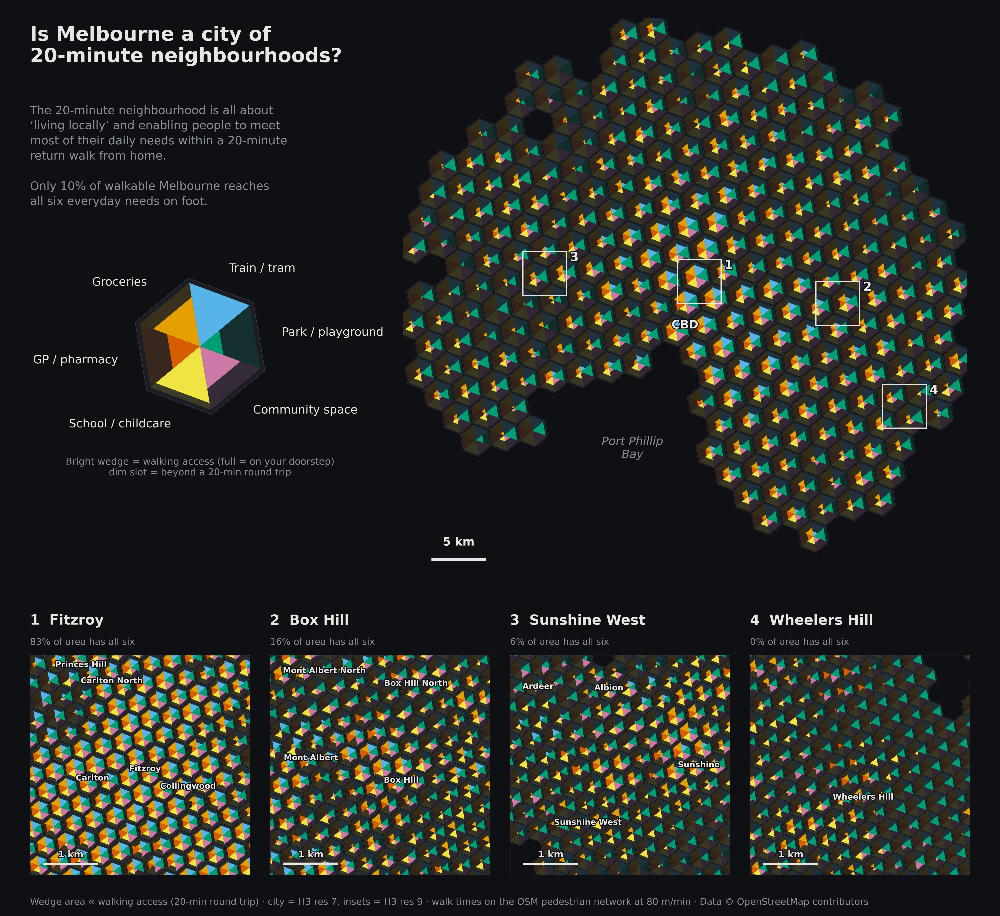

In [314]:
RIVER = "#7fb3d5"
YARRA_LABEL_LNGLAT = (145.03, -37.805)


def draw_rail(ax, ctx, lw_rail, lw_tram):
    ax.add_collection(LineCollection(ctx["tram"], colors="#9aa3ad", linewidths=lw_tram, alpha=0.35, zorder=3))
    ax.add_collection(LineCollection(ctx["rail"], colors="#e8e6e1", linewidths=lw_rail, alpha=0.5, zorder=3))


def with_xy(df):
    ll = np.array([h3.cell_to_latlng(c) for c in df["cell"]])
    df = df.copy()
    df["fx"], df["fy"] = to_proj.transform(ll[:, 1], ll[:, 0])
    return df


def scalebar(ax, length_m, label, loc=(0.06, 0.05), fontsize=16, lw=4):
    x0, x1 = ax.get_xlim(); y0, y1 = ax.get_ylim()
    x, y = x0 + loc[0] * (x1 - x0), y0 + loc[1] * (y1 - y0)
    ax.plot([x, x + length_m], [y, y], color=FG, lw=lw, solid_capstyle="butt", zorder=8)
    ax.text(x + length_m / 2, y + 0.02 * (y1 - y0), label, color=FG, fontsize=fontsize, weight="bold",
            ha="center", va="bottom", zorder=8, path_effects=HALO)


def inset_extent(ins):
    x, y = to_proj.transform(ins["latlng"][1], ins["latlng"][0])
    r = INSET_RADIUS_KM * 1000
    return (x - r, y - r, x + r, y + r)


def in_extent(df, ext, pad=0):
    return df[(df["fx"] > ext[0] - pad) & (df["fx"] < ext[2] + pad) &
              (df["fy"] > ext[1] - pad) & (df["fy"] < ext[3] + pad)]


def place_labels(ax, items, fontsize=10, pad_px=4, **style):
    """Draw labels without overlaps. items = [(x, y, text, extra_style_dict), ...] in priority order.
    Each label tries its own spot, then just above, then just below; if all collide it is skipped.
    Call after the axes limits are set."""
    fig = ax.figure
    fig.canvas.draw_idle()
    bb = ax.get_window_extent()
    (x0, x1), (y0, y1) = ax.get_xlim(), ax.get_ylim()
    sx, sy = bb.width / (x1 - x0), bb.height / (y1 - y0)       # pixels per data unit
    placed = []
    for x, y, text, extra in items:
        kw = {"fontsize": fontsize, **style, **extra}
        px = kw["fontsize"] * fig.dpi / 72
        w = (len(text) * 0.58 * px + 2 * pad_px) / sx
        h = (1.25 * px + pad_px) / sy
        for dy in (0, h, -h):
            r = (x - w / 2, y + dy - h / 2, x + w / 2, y + dy + h / 2)
            inside = x0 <= r[0] and r[2] <= x1 and y0 <= r[1] and r[3] <= y1
            if inside and all(r[2] < q[0] or r[0] > q[2] or r[3] < q[1] or r[1] > q[3] for q in placed):
                placed.append(r)
                ax.text(x, y + dy, text, ha="center", va="center", **kw)
                break


def council_scores(fine, councils):
    import geopandas as gpd
    pts = gpd.GeoDataFrame(fine[["complete"]], geometry=gpd.points_from_xy(fine["fx"], fine["fy"]), crs=CRS_PROJ)
    j = gpd.sjoin(pts, councils[["short", "geometry"]], predicate="within")
    stats = j.groupby("short")["complete"].agg(complete="mean", cells="size").reset_index()
    return councils.drop(columns=["complete", "cells"], errors="ignore").merge(stats, on="short", how="left")


def draw_ranking(fig, rect, names, values, fs=11):
    """Ranked bar list: name · bar · percentage."""
    ax = fig.add_axes(rect)
    ax.axis("off")
    n = len(names)
    ax.set_xlim(0, 1); ax.set_ylim(n - 0.4, -0.6)
    for i, (name, v) in enumerate(zip(names, values)):
        ax.text(0, i, name, color=FG, fontsize=fs, va="center")
        ax.add_patch(Rectangle((0.40, i - 0.28), 0.49, 0.56, fc="#1a1d23", ec="none"))
        ax.add_patch(Rectangle((0.40, i - 0.28), 0.49 * v, 0.56, fc=FG, ec="none"))
        ax.text(0.91, i, f"{v:.0%}", color=FG, fontsize=fs, va="center")


def draw_councils(ax, councils, lw=1.0, label_fs=11, first_items=()):
    lines = []
    for geom in councils.geometry:
        for part in getattr(geom, "geoms", [geom]):
            lines.append(np.asarray(part.exterior.coords))
    ax.add_collection(LineCollection(lines, colors="#e8e6e1", linewidths=lw, alpha=0.55, zorder=4))
    items = list(first_items)
    for _, r in councils.assign(_a=councils.area).sort_values("_a", ascending=False).iterrows():
        pt = r.geometry.representative_point()
        items.append((pt.x, pt.y, r["short"], {}))
    place_labels(ax, items, fontsize=label_fs, color=FG, weight="bold", zorder=9, path_effects=HALO)


def poster(city, fine, inset_hex, ctx, councils, ref, path, headline):
    W, H = 24, 22
    fig = plt.figure(figsize=(W, H), facecolor=BG)

    # ── top-left: title, finding, legend ──
    fig.text(0.03, 0.972, "Is Melbourne a city of\n20-minute neighbourhoods?", color=FG, fontsize=34,
             weight="bold", va="top", linespacing=1.15)
    fig.text(0.03, 0.885, headline, color=MUTED, fontsize=20, va="top", linespacing=1.45)
    draw_legend(fig, [0.02, 0.48, 0.36, 0.28], ref, fs=20)

    # ── top-right: whole city ──
    ax = fig.add_axes([0.39, 0.365, 0.59, 0.615])
    draw_hexes(ax, city, ref, outline_lw=0.5)
    if SHOW_RAIL:
        draw_rail(ax, ctx, 0.5, 0.25)
    poly_proj, _ = study_area()
    minx, miny, maxx, maxy = poly_proj.bounds
    ax.set_xlim(minx - 800, maxx + 800); ax.set_ylim(miny - 800, maxy + 800)
    cx, cy = to_proj.transform(CENTER_LATLNG[1], CENTER_LATLNG[0])
    cbd = (cx, cy, "CBD", {"fontsize": 20, "color": "#f0e442"})
    if SHOW_COUNCILS and councils is not None and len(councils):
        draw_councils(ax, councils, lw=1.1, label_fs=11.5, first_items=[cbd])
    else:
        ax.text(cx, cy - 1800, "CBD", color=FG, fontsize=20, weight="bold", ha="center", va="top", zorder=9,
                path_effects=HALO, clip_on=True)
    if ctx.get("yarra"):
        ax.add_collection(LineCollection(ctx["yarra"], colors=RIVER, linewidths=2.2, alpha=0.95, zorder=5,
                                         capstyle="round", joinstyle="round"))
        pts = np.vstack(ctx["yarra"])
        lx, ly = to_proj.transform(*YARRA_LABEL_LNGLAT)
        i = np.argmin(np.hypot(pts[:, 0] - lx, pts[:, 1] - ly))       # label sits on the river near Kew
        ax.text(pts[i, 0], pts[i, 1] + 900, "Yarra River", color=RIVER, fontsize=13, style="italic",
                weight="bold", ha="center", va="bottom", zorder=9, path_effects=HALO, clip_on=True)
    bx, by = to_proj.transform(144.905, -37.935)
    ax.text(bx, by, "Port Phillip\nBay", color=MUTED, fontsize=20, style="italic", ha="center", va="center",
            zorder=9, clip_on=True)
    for n, ins in enumerate(INSETS, 1):
        e = inset_extent(ins)
        ax.add_patch(Rectangle((e[0], e[1]), e[2] - e[0], e[3] - e[1], fill=False, ec=FG, lw=2, zorder=9))
        ax.text(e[2] + 300, e[3], str(n), color=FG, fontsize=22, weight="bold", ha="left", va="top",
                zorder=9, path_effects=HALO)
    scalebar(ax, 5000, "5 km", loc=(0.05, 0.04), fontsize=20, lw=5)

    # ── bottom row: four insets ──
    w = 0.22
    h = w * W / H
    for n, ins in enumerate(INSETS, 1):
        x0, y0 = 0.03 + (n - 1) * 0.24, 0.045
        e = inset_extent(ins)
        sel = in_extent(inset_hex, e, pad=600)
        iax = fig.add_axes([x0, y0, w, h])
        draw_hexes(iax, sel, ref, outline_lw=0.8)
        if SHOW_RAIL:
            draw_rail(iax, ctx, 1.2, 0.7)
        iax.set_xlim(e[0], e[2]); iax.set_ylim(e[1], e[3])
        pl = ctx["places"]
        pl = pl[(pl.x > e[0]) & (pl.x < e[2]) & (pl.y > e[1] + 0.15 * (e[3] - e[1])) & (pl.y < e[3])]
        place_labels(iax, [(p.x, p.y, p["name"], {}) for _, p in pl.iterrows()], fontsize=14,
                     color=FG, weight="bold", zorder=9, path_effects=HALO)
        scalebar(iax, 1000, "1 km", fontsize=16, lw=4)
        iax.add_patch(Rectangle((0, 0), 1, 1, transform=iax.transAxes, fill=False, ec="#3a3f48", lw=1, zorder=10))
        share = in_extent(fine, e)["complete"].mean()
        fig.text(x0, y0 + h + 0.030, f"{n}  {ins['name']}", color=FG, fontsize=24, weight="bold", va="bottom")
        fig.text(x0, y0 + h + 0.009, f"{share:.0%} of area has all six",
                 color=MUTED, fontsize=16, va="bottom")

    trip = f"{2 * CUTOFF_MIN}-min round trip"
    fig.text(0.03, 0.015,
             f"Wedge area ∝ walking access ({trip}) · city = H3 res {CITY_RES}, insets = H3 res {INSET_RES} · "
             "walk times on the OSM pedestrian network at 80 m/min · Data © OpenStreetMap contributors",
             color=MUTED, fontsize=16, va="center")
    fig.savefig(path, dpi=250, facecolor=BG)
    plt.close(fig)
    print(f"✓ wrote {path}")


city = aggregate(fine, CITY_RES)
ref = _reference_angle(city["cell"].iloc[len(city) // 2])
complete = fine["complete"].mean()
headline = (
    "The 20-minute neighbourhood is all about\n"
    "‘living locally’ and enabling people to meet\n"
    "most of their daily needs within a 20-minute\n"
    "return walk from home.\n\n"
    f"Only {complete:.0%} of walkable Melbourne reaches\n"
    "all six everyday needs on foot."
)
poster_png = OUT / "melbourne_20mn_poster.png"
inset_hex = with_xy(aggregate(fine, INSET_RES))
poster(city, fine, inset_hex, ctx, councils, ref, poster_png, headline)
display(Image(filename=poster_png, width=1100))

## 9. Suburb scorecard
The ten most and least complete suburbs. Each one is drawn as a single hexagon using its average scores.

✓ wrote output\melbourne_20mn_suburbs.png


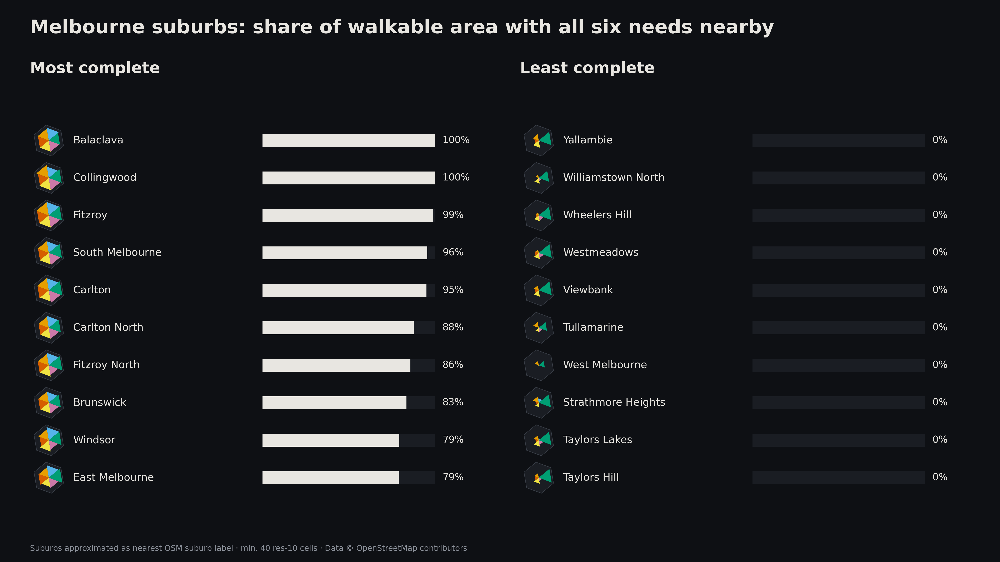

In [270]:
def mini_hex(ax, x, y, scores, ref, r=0.42):
    angs = ref + np.arange(6) * np.pi / 3
    v = np.column_stack([x + r * np.cos(angs), y + r * np.sin(angs)])
    c = np.array([x, y])
    ax.add_patch(plt.Polygon(v, closed=True, fc="#1a1d23", ec="#3a3f48", lw=0.6))
    for k, key in enumerate(KEYS):
        f = math.sqrt(max(scores[key], 0))
        a, b = v[k], v[(k + 1) % 6]
        ax.add_patch(plt.Polygon([c, c + f * (a - c), c + f * (b - c)], closed=True,
                                 fc=CATEGORIES[key]["color"], ec="none"))


def scorecard(table, ref, path, n=10):
    fig = plt.figure(figsize=(16, 9), facecolor=BG)
    groups = [("Most complete", table.head(n)), ("Least complete", table.tail(n).iloc[::-1])]
    for col, (title, t) in enumerate(groups):
        ax = fig.add_axes([0.03 + col * 0.49, 0.06, 0.45, 0.78])
        ax.set_facecolor(BG); ax.axis("off"); ax.set_aspect("equal")
        ax.set_xlim(0, 12); ax.set_ylim(0, n + 0.6)
        for i, (name, row) in enumerate(t.iterrows()):
            y = n - i - 0.2
            mini_hex(ax, 0.5, y, row, ref)
            ax.text(1.15, y, name, color=FG, fontsize=12, va="center")
            ax.add_patch(Rectangle((6.2, y - 0.17), 4.6, 0.34, fc="#1a1d23", ec="none"))
            ax.add_patch(Rectangle((6.2, y - 0.17), 4.6 * row["complete"], 0.34, fc=FG, ec="none"))
            ax.text(11.0, y, f"{row['complete']:.0%}", color=FG, fontsize=11, va="center")
        fig.text(0.03 + col * 0.49, 0.87, title, color=FG, fontsize=18, weight="bold")
    fig.text(0.03, 0.95, "Melbourne suburbs: share of walkable area with all six needs nearby",
             color=FG, fontsize=22, weight="bold", va="center")
    fig.text(0.03, 0.02, f"Suburbs approximated as nearest OSM suburb label · min. {40} res-{FINE_RES} cells · "
             "Data © OpenStreetMap contributors", color=MUTED, fontsize=9)
    fig.savefig(path, dpi=300, facecolor=BG)
    plt.close(fig)
    print(f"✓ wrote {path}")


score_png = OUT / "melbourne_20mn_suburbs.png"
scorecard(suburbs, ref, score_png)
display(Image(filename=score_png, width=1000))

## 10. Inner city at res 8 (optional second image)

✓ wrote output\melbourne_20mn_inner.png


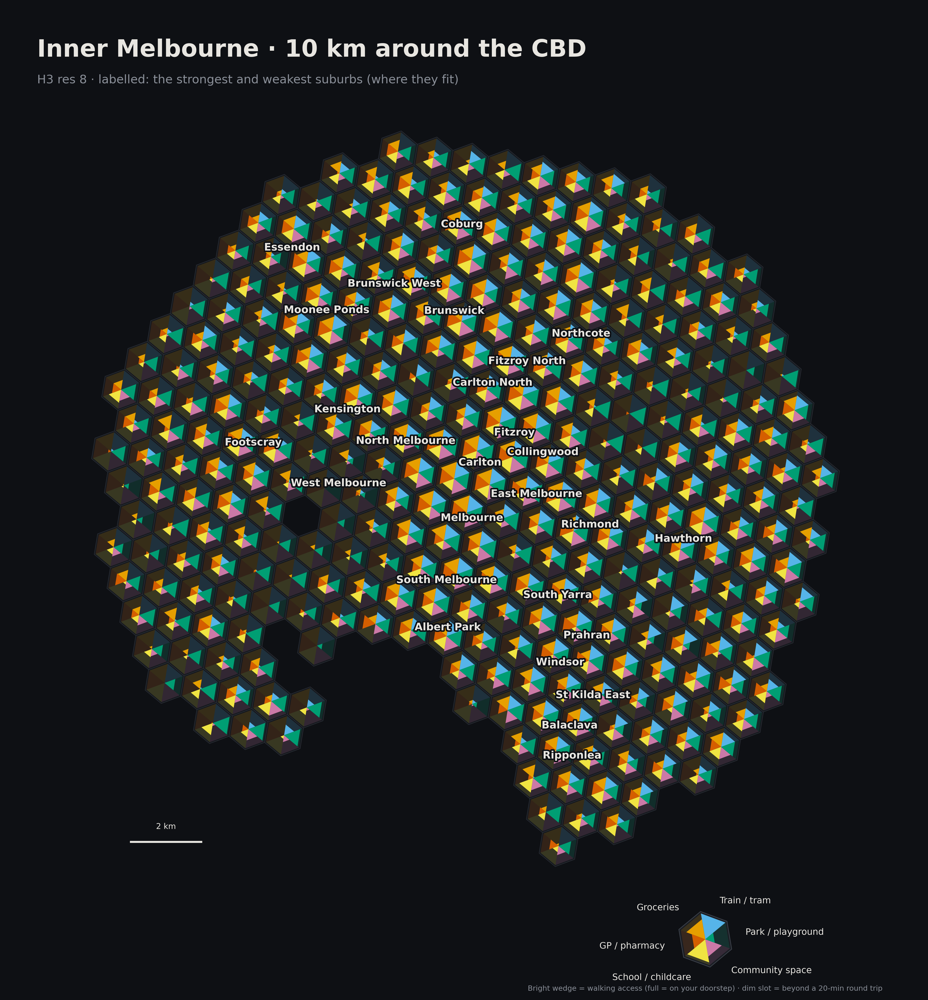

In [272]:
inner = aggregate(fine, INNER_RES)
_ll = np.array([h3.cell_to_latlng(c) for c in inner["cell"]])
inner["fx"], inner["fy"] = to_proj.transform(_ll[:, 1], _ll[:, 0])
cx, cy = to_proj.transform(CENTER_LATLNG[1], CENTER_LATLNG[0])
R = INNER_RADIUS_KM * 1000
inner = inner[np.hypot(inner["fx"] - cx, inner["fy"] - cy) <= R]

fig = plt.figure(figsize=(13, 14), facecolor=BG)
ax = fig.add_axes([0.03, 0.12, 0.94, 0.76])
draw_hexes(ax, inner, ref, outline_lw=0.5)
if SHOW_RAIL:
    draw_rail(ax, ctx, 0.7, 0.35)
ax.set_xlim(cx - R - 500, cx + R + 500); ax.set_ylim(cy - R - 500, cy + R + 500)
# best and worst suburbs first, then any others that still fit without overlapping
order = list(suburbs.index[:10]) + list(suburbs.index[::-1][:10]) + list(suburbs.index[10:-10])
pl = ctx["places"].set_index("name")
items = [(pl.at[n, "x"], pl.at[n, "y"], n, {}) for n in dict.fromkeys(order)
         if n in pl.index and np.hypot(pl.at[n, "x"] - cx, pl.at[n, "y"] - cy) < R - 800]
place_labels(ax, items[:28], fontsize=10.5, color=FG, weight="bold", zorder=9, path_effects=HALO)
scalebar(ax, 2000, "2 km")
fig.text(0.04, 0.95, f"Inner Melbourne · {INNER_RADIUS_KM} km around the CBD", color=FG, fontsize=24, weight="bold", va="center")
fig.text(0.04, 0.92, f"H3 res {INNER_RES} · labelled: the strongest and weakest suburbs (where they fit)", color=MUTED, fontsize=12, va="center")
draw_legend(fig, [0.55, 0.01, 0.42, 0.1], ref)
inner_png = OUT / "melbourne_20mn_inner.png"
fig.savefig(inner_png, dpi=300, facecolor=BG); plt.close(fig)
print(f"✓ wrote {inner_png}")
display(Image(filename=inner_png, width=900))

## 11. The raw data: one map per layer
Every amenity location used in the analysis, with no hexagons and no scoring. Use it to sanity-check OSM coverage: a suspiciously empty area usually means missing data, not a real gap. Parks are drawn as points along their edges, sampled every 50 m.

· loading cached amenities cache\amenities_pbf_r25_c10_0b338c.npz


C:\Users\User\AppData\Local\Temp\ipykernel_20028\746053131.py:5: DeprecationWarning: The 'shapely.ops.transform()' function is deprecated. Use 'shapely.transform()' or 'shapely.transform_coordseq()' instead. See https://shapely.readthedocs.io/en/latest/manual.html#shapely.ops.transform for more details.
  poly_wgs = shp_transform(to_wgs.transform, poly_proj)


✓ wrote output\melbourne_20mn_layers.png


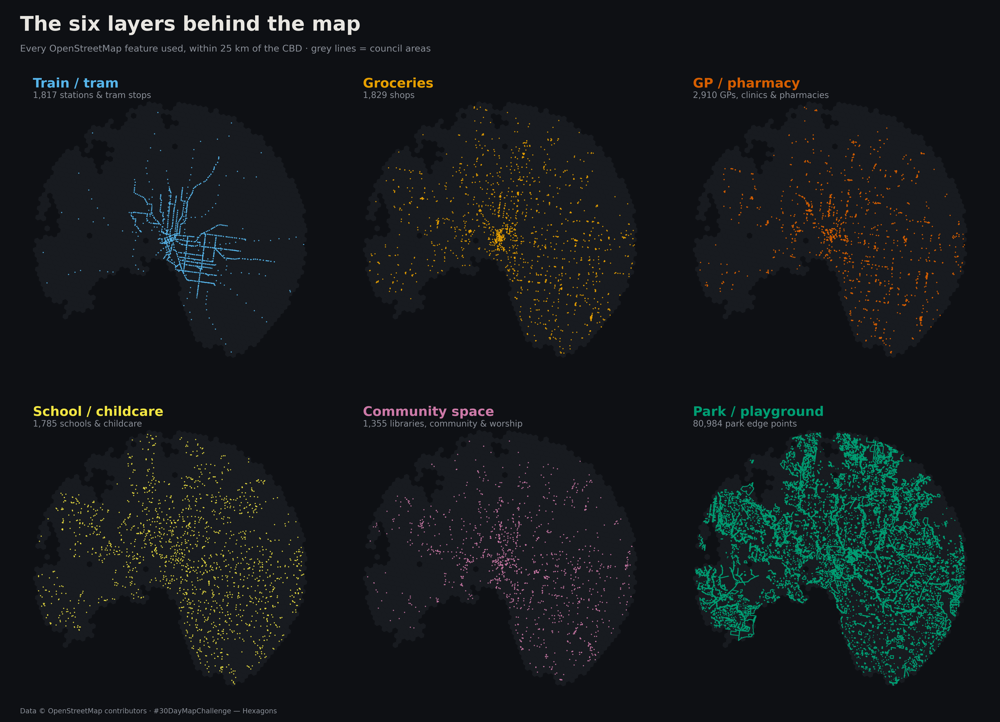

In [274]:
amen = load_amenities()
poly_proj, _ = study_area()
cx, cy = to_proj.transform(CENTER_LATLNG[1], CENTER_LATLNG[0])
R = RADIUS_KM * 1000
land = aggregate(fine, 8)
land_outlines = [_ordered(_cell_vertices(c), ref)[1] for c in land["cell"]]
council_lines = []
if councils is not None and len(councils):
    for geom in councils.geometry:
        for part in getattr(geom, "geoms", [geom]):
            council_lines.append(np.asarray(part.exterior.coords))

units = {"transit": "stations & tram stops", "groceries": "shops", "health": "GPs, clinics & pharmacies",
         "school": "schools & childcare", "community": "libraries, community & worship",
         "park": "park edge points"}

fig = plt.figure(figsize=(18, 13), facecolor=BG)
fig.text(0.02, 0.965, "The six layers behind the map", color=FG, fontsize=26, weight="bold", va="center")
fig.text(0.02, 0.932, f"Every OpenStreetMap feature used, within {RADIUS_KM} km of the CBD · grey lines = council areas",
         color=MUTED, fontsize=12, va="center")
for k, key in enumerate(KEYS):
    row, col = divmod(k, 3)
    ax = fig.add_axes([0.02 + col * 0.33, 0.48 - row * 0.455, 0.30, 0.38])
    ax.set_facecolor(BG); ax.set_aspect("equal"); ax.axis("off")
    ax.add_collection(PolyCollection(land_outlines, facecolors="#181b20", edgecolors="none", zorder=1))
    if council_lines:
        ax.add_collection(LineCollection(council_lines, colors="#3a3f48", linewidths=0.6, zorder=2))
    pts = amen[key]
    pts = pts[np.hypot(pts[:, 0] - cx, pts[:, 1] - cy) <= R] if len(pts) else pts
    size = 1.2 if len(pts) > 3000 else 2.5
    if len(pts):
        ax.scatter(pts[:, 0], pts[:, 1], s=size, c=CATEGORIES[key]["color"], linewidths=0, alpha=0.9, zorder=3)
    ax.set_xlim(cx - R - 500, cx + R + 500); ax.set_ylim(cy - R - 500, cy + R + 500)
    ax.text(0, 1.04, CATEGORIES[key]["label"], transform=ax.transAxes, color=CATEGORIES[key]["color"],
            fontsize=17, weight="bold", va="bottom")
    ax.text(0, 1.005, f"{len(pts):,} {units[key]}", transform=ax.transAxes, color=MUTED, fontsize=11, va="bottom")
fig.text(0.02, 0.012, "Data © OpenStreetMap contributors · #30DayMapChallenge — Hexagons", color=MUTED, fontsize=9)
layers_png = OUT / "melbourne_20mn_layers.png"
fig.savefig(layers_png, dpi=250, facecolor=BG); plt.close(fig)
print(f"✓ wrote {layers_png}")
display(Image(filename=layers_png, width=1100))